# Лабораторная работа 3
Самарин НА КИ25-04-3М

### 1. Инициализация

На данном этапе выполняется подготовка среды для работы с большими данными. Создаётся сессия Apache Spark, подключаются необходимые библиотеки Python для обработки, анализа и визуализации данных. Настраиваются параметры Spark для локального выполнения вычислений.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql import types as T
import os


In [2]:
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"
os.environ["HADOOP_HOME"] = "C:\\hadoop"
os.environ["hadoop.home.dir"] = "C:\\hadoop"
os.environ["PATH"] += os.pathsep + "C:\\hadoop\\bin"

spark = (
    SparkSession.builder
    .appName("Olist_LR3_Data_Preprocessing")
    .master("local[*]")
    .config("spark.driver.host", "127.0.0.1")
    .config("spark.driver.bindAddress", "127.0.0.1")
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.ui.enabled", "false")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("WARN")

# Проверяем что spark работает
print("Spark version:", spark.version)
print("Master:", spark.sparkContext.master)
print("Application:", spark.sparkContext.appName)
print("Spark UI:", spark.sparkContext.uiWebUrl)
spark.range(3).show()

Spark version: 4.3.0
Master: local[*]
Application: Olist_LR3_Data_Preprocessing
Spark UI: None
+---+
| id|
+---+
|  0|
|  1|
|  2|
+---+



### 2. Загрузка исходных данных

В систему загружаются исходные CSV-файлы датасета Brazilian E-Commerce Public Dataset by Olist. Данные содержат информацию о заказах, товарах, покупателях, отзывах и категориях товаров. Для каждого файла создаётся отдельный DataFrame, позволяющий выполнять дальнейшую обработку данных.

In [3]:
DATA_PATH = "../data/olist"

orders = spark.read.csv(
    f"{DATA_PATH}/olist_orders_dataset.csv",
    header=True,
    inferSchema=True,
    multiLine=True,
    quote='"',
    escape='"'
)

order_items = spark.read.csv(
    f"{DATA_PATH}/olist_order_items_dataset.csv",
    header=True,
    inferSchema=True,
    multiLine=True,
    quote='"',
    escape='"'
)

products = spark.read.csv(
    f"{DATA_PATH}/olist_products_dataset.csv",
    header=True,
    inferSchema=True,
    multiLine=True,
    quote='"',
    escape='"'
)

customers = spark.read.csv(
    f"{DATA_PATH}/olist_customers_dataset.csv",
    header=True,
    inferSchema=True,
    multiLine=True,
    quote='"',
    escape='"'
)

reviews = spark.read.csv(
    f"{DATA_PATH}/olist_order_reviews_dataset.csv",
    header=True,
    inferSchema=True,
    multiLine=True,
    quote='"',
    escape='"'
)


category_translation = spark.read.csv(
    f"{DATA_PATH}/product_category_name_translation.csv",
    header=True,
    inferSchema=True,
    multiLine=True,
    quote='"',
    escape='"'
)

In [4]:
datasets = {
    "orders": orders,
    "order_items": order_items,
    "products": products,
    "customers": customers,
    "reviews": reviews,
    "category_translation": category_translation
}

for name, df in datasets.items():
    print(f"\n{name}")
    print("Количество строк:", df.count())
    print("Количество столбцов:", len(df.columns))
    print("Столбцы:", df.columns)


orders
Количество строк: 99441
Количество столбцов: 8
Столбцы: ['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

order_items
Количество строк: 112650
Количество столбцов: 7
Столбцы: ['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

products
Количество строк: 32951
Количество столбцов: 9
Столбцы: ['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']

customers
Количество строк: 99441
Количество столбцов: 5
Столбцы: ['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']

reviews
Количество строк: 99224
Количество столбцов: 7
Столбцы: ['review_id', 'order_id', 'review_score', 'review_comment_title', 'review

In [5]:
orders.printSchema()
order_items.printSchema()
products.printSchema()
customers.printSchema()
reviews.printSchema()

root
 |-- order_id: string (nullable = true)
 |-- customer_id: string (nullable = true)
 |-- order_status: string (nullable = true)
 |-- order_purchase_timestamp: timestamp (nullable = true)
 |-- order_approved_at: timestamp (nullable = true)
 |-- order_delivered_carrier_date: timestamp (nullable = true)
 |-- order_delivered_customer_date: timestamp (nullable = true)
 |-- order_estimated_delivery_date: timestamp (nullable = true)

root
 |-- order_id: string (nullable = true)
 |-- order_item_id: integer (nullable = true)
 |-- product_id: string (nullable = true)
 |-- seller_id: string (nullable = true)
 |-- shipping_limit_date: timestamp (nullable = true)
 |-- price: double (nullable = true)
 |-- freight_value: double (nullable = true)

root
 |-- product_id: string (nullable = true)
 |-- product_category_name: string (nullable = true)
 |-- product_name_lenght: integer (nullable = true)
 |-- product_description_lenght: integer (nullable = true)
 |-- product_photos_qty: integer (nullable 

In [6]:
orders.show(5, truncate=False)
order_items.show(5, truncate=False)
products.show(5, truncate=False)
customers.show(5, truncate=False)
reviews.show(5, truncate=False)

+--------------------------------+--------------------------------+------------+------------------------+-------------------+----------------------------+-----------------------------+-----------------------------+
|order_id                        |customer_id                     |order_status|order_purchase_timestamp|order_approved_at  |order_delivered_carrier_date|order_delivered_customer_date|order_estimated_delivery_date|
+--------------------------------+--------------------------------+------------+------------------------+-------------------+----------------------------+-----------------------------+-----------------------------+
|e481f51cbdc54678b7cc49136f2d6af7|9ef432eb6251297304e76186b10a928d|delivered   |2017-10-02 10:56:33     |2017-10-02 11:07:15|2017-10-04 19:55:00         |2017-10-10 21:25:13          |2017-10-18 00:00:00          |
|53cdb2fc8bc7dce0b6741e2150273451|b0830fb4747a6c6d20dea0b8c802d7ef|delivered   |2018-07-24 20:41:37     |2018-07-26 03:24:27|2018-07-26 14:3

### 3. Исследование качества данных

Проводится первичный анализ загруженных данных с целью выявления проблем качества. Проверяется структура таблиц, типы данных, количество записей, наличие пропусков, дубликатов и некорректных значений. Полученные результаты позволяют определить необходимость дальнейшей очистки данных.

#### Проверка пропущенных значений

In [7]:
def missing_values_report(df):
    total_rows = df.count()

    expressions = []

    for column in df.columns:
        expressions.append(
            F.sum(
                F.when(
                    F.col(column).isNull(),
                    1
                ).otherwise(0)
            ).alias(column)
        )

    missing = df.select(expressions).collect()[0]

    result = []

    for column in df.columns:
        missing_count = missing[column]

        result.append({
            "column": column,
            "missing_count": missing_count,
            "missing_percent": round(
                missing_count / total_rows * 100, 2
            )
        })

    return pd.DataFrame(result).sort_values(
        "missing_percent",
        ascending=False
    )

In [8]:
missing_values_report(orders)

,column,missing_count,missing_percent
6,order_delivered_customer_date,2965,2.98
5,order_delivered_carrier_date,1783,1.79
4,order_approved_at,160,0.16
0,order_id,0,0.00
3,order_purchase_timestamp,0,0.00
2,order_status,0,0.00
1,customer_id,0,0.00
7,order_estimated_delivery_date,0,0.00


In [9]:
missing_values_report(order_items)

,column,missing_count,missing_percent
0,order_id,0,0.0
1,order_item_id,0,0.0
2,product_id,0,0.0
3,seller_id,0,0.0
4,shipping_limit_date,0,0.0
5,price,0,0.0
6,freight_value,0,0.0


In [10]:
missing_values_report(products)

,column,missing_count,missing_percent
1,product_category_name,610,1.85
3,product_description_lenght,610,1.85
2,product_name_lenght,610,1.85
4,product_photos_qty,610,1.85
5,product_weight_g,2,0.01
7,product_height_cm,2,0.01
6,product_length_cm,2,0.01
8,product_width_cm,2,0.01
0,product_id,0,0.00


In [11]:
missing_values_report(reviews)

,column,missing_count,missing_percent
3,review_comment_title,87656,88.34
4,review_comment_message,58247,58.70
0,review_id,0,0.00
2,review_score,0,0.00
1,order_id,0,0.00
5,review_creation_date,0,0.00
6,review_answer_timestamp,0,0.00


#### Проверка дубликатов

In [12]:
def duplicate_report(df, key_columns):
    return (
        df.groupBy(*key_columns)
        .count()
        .filter(F.col("count") > 1)
    )

In [13]:
duplicate_report(
    orders,
    ["order_id"]
).show()

+--------+-----+
|order_id|count|
+--------+-----+
+--------+-----+



In [14]:
duplicate_report(
    customers,
    ["customer_id"]
).show()

+-----------+-----+
|customer_id|count|
+-----------+-----+
+-----------+-----+



In [15]:
duplicate_report(
    products,
    ["product_id"]
).show()

+----------+-----+
|product_id|count|
+----------+-----+
+----------+-----+



In [16]:
duplicate_report(
    order_items,
    ["order_id", "order_item_id"]
).show()

+--------+-------------+-----+
|order_id|order_item_id|count|
+--------+-------------+-----+
+--------+-------------+-----+



### 4. Очистка и предобработка данных

На данном этапе выполняется устранение выявленных проблем качества данных. Удаляются дубликаты, обрабатываются пропущенные значения, корректируются типы данных, проверяются числовые показатели на наличие некорректных значений. Также выполняется преобразование временных полей для возможности проведения временного анализа.

#### Очистка таблицы заказов

In [17]:
orders_clean = orders.dropDuplicates(["order_id"])

date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for column in date_columns:
    orders_clean = orders_clean.withColumn(
        column,
        F.to_timestamp(F.col(column))
    )

In [18]:
orders_clean.printSchema()

root
 |-- order_id: string (nullable = true)
 |-- customer_id: string (nullable = true)
 |-- order_status: string (nullable = true)
 |-- order_purchase_timestamp: timestamp (nullable = true)
 |-- order_approved_at: timestamp (nullable = true)
 |-- order_delivered_carrier_date: timestamp (nullable = true)
 |-- order_delivered_customer_date: timestamp (nullable = true)
 |-- order_estimated_delivery_date: timestamp (nullable = true)



Удалим записи, не содержащие идентификатор заказа или дату его оформления

In [19]:
orders_clean = orders_clean.filter(
    F.col("order_id").isNotNull()
    & F.col("order_purchase_timestamp").isNotNull()
)

#### Очистка таблицы товаров

In [20]:
products_clean = products.dropDuplicates(["product_id"])

In [21]:
products_clean = products_clean.fillna({
    "product_category_name": "unknown"
})

#### Очистка таблицы покупателей

In [22]:
customers_clean = customers.dropDuplicates(
    ["customer_id"]
)

In [23]:
missing_values_report(customers_clean)

,column,missing_count,missing_percent
0,customer_id,0,0.0
1,customer_unique_id,0,0.0
2,customer_zip_code_prefix,0,0.0
3,customer_city,0,0.0
4,customer_state,0,0.0


#### Очистка таблицы товаров в заказах

In [24]:
order_items_clean = order_items.dropDuplicates(
    ["order_id", "order_item_id"]
)

In [25]:
order_items_clean.filter(
    (F.col("price") < 0)
    | (F.col("freight_value") < 0)
).show()

+--------+-------------+----------+---------+-------------------+-----+-------------+
|order_id|order_item_id|product_id|seller_id|shipping_limit_date|price|freight_value|
+--------+-------------+----------+---------+-------------------+-----+-------------+
+--------+-------------+----------+---------+-------------------+-----+-------------+



В рамках данного набора данных отрицательная стоимость товара или доставки является некорректной.

In [26]:
order_items_clean = order_items_clean.filter(
    (F.col("price") >= 0)
    & (F.col("freight_value") >= 0)
)

#### Очистка отзывов

In [27]:
reviews_clean = reviews.dropDuplicates(
    ["review_id"]
)

Оценки должны находиться в диапазоне от 1 до 5.

In [28]:
reviews_clean.filter(
    (F.col("review_score") < 1)
    | (F.col("review_score") > 5)
).show()

+---------+--------+------------+--------------------+----------------------+--------------------+-----------------------+
|review_id|order_id|review_score|review_comment_title|review_comment_message|review_creation_date|review_answer_timestamp|
+---------+--------+------------+--------------------+----------------------+--------------------+-----------------------+
+---------+--------+------------+--------------------+----------------------+--------------------+-----------------------+



Для текстовых отзывов можно удалить лишние пробелы и заменить отсутствующие значения пустой строкой:

In [29]:
reviews_clean = reviews_clean.withColumn(
    "review_comment_message",
    F.trim(
        F.col("review_comment_message")
    )
)

reviews_clean = reviews_clean.fillna({
    "review_comment_message": ""
})

### 5. Объединение таблиц

Для формирования единого аналитического набора данных выполняется объединение исходных таблиц по ключевым идентификаторам. Связываются данные о заказах, товарах, покупателях и отзывах. Это позволяет анализировать взаимосвязи между различными характеристиками электронной коммерции.

Основой объединения будет таблица заказов.

Связи между таблицами:
- orders.order_id → order_items.order_id;
- order_items.product_id → products.product_id;
- orders.customer_id → customers.customer_id;
- orders.order_id → reviews.order_id;
- products.product_category_name → category_translation.product_category_name.

In [30]:
orders_items = orders_clean.join(
    order_items_clean,
    on="order_id",
    how="inner"
)

In [31]:
orders_products = orders_items.join(
    products_clean,
    on="product_id",
    how="left"
)

In [32]:
orders_customers = orders_products.join(
    customers_clean,
    on="customer_id",
    how="left"
)

In [33]:
orders_reviews = orders_customers.join(
    reviews_clean,
    on="order_id",
    how="left"
)

In [34]:
orders_full = orders_reviews.join(
    category_translation,
    on="product_category_name",
    how="left"
)

In [35]:
orders_full.printSchema()

root
 |-- product_category_name: string (nullable = true)
 |-- order_id: string (nullable = true)
 |-- customer_id: string (nullable = true)
 |-- product_id: string (nullable = true)
 |-- order_status: string (nullable = true)
 |-- order_purchase_timestamp: timestamp (nullable = true)
 |-- order_approved_at: timestamp (nullable = true)
 |-- order_delivered_carrier_date: timestamp (nullable = true)
 |-- order_delivered_customer_date: timestamp (nullable = true)
 |-- order_estimated_delivery_date: timestamp (nullable = true)
 |-- order_item_id: integer (nullable = true)
 |-- seller_id: string (nullable = true)
 |-- shipping_limit_date: timestamp (nullable = true)
 |-- price: double (nullable = true)
 |-- freight_value: double (nullable = true)
 |-- product_name_lenght: integer (nullable = true)
 |-- product_description_lenght: integer (nullable = true)
 |-- product_photos_qty: integer (nullable = true)
 |-- product_weight_g: integer (nullable = true)
 |-- product_length_cm: integer (null

In [36]:
orders_full.show(10, truncate=False)

+---------------------------+--------------------------------+--------------------------------+--------------------------------+------------+------------------------+-------------------+----------------------------+-----------------------------+-----------------------------+-------------+--------------------------------+-------------------+------+-------------+-------------------+--------------------------+------------------+----------------+-----------------+-----------------+----------------+--------------------------------+------------------------+---------------------+--------------+--------------------------------+------------+--------------------+----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+--------------------+-----------------------+-----------------------------+
|product_category_name      |order_id                        |customer_id           

In [37]:
print("Исходные заказы:", orders_clean.count())
print("Итоговый набор:", orders_full.count())

Исходные заказы: 99441
Итоговый набор: 112952


### 6. Формирование аналитических показателей

На основе очищенных и объединённых данных рассчитываются основные аналитические показатели. Выполняется анализ динамики продаж, количества заказов, выручки, популярности категорий товаров, распределения покупателей по регионам, оценок пользователей и сроков доставки. Полученные агрегированные данные используются для выявления закономерностей и тенденций.

#### Динамика продаж

Рассчитаем количество заказов и суммарную стоимость товаров по месяцам.

In [38]:
sales_by_month = (
    orders_clean
    .withColumn(
        "month",
        F.date_format(
            "order_purchase_timestamp",
            "yyyy-MM"
        )
    )
    .join(
        order_items_clean,
        on="order_id",
        how="inner"
    )
    .groupBy("month")
    .agg(
        F.countDistinct("order_id").alias("orders_count"),
        F.sum("price").alias("revenue"),
        F.sum("freight_value").alias("freight")
    )
    .orderBy("month")
)

In [39]:
sales_by_month.show(30, truncate=False)

+-------+------------+------------------+------------------+
|month  |orders_count|revenue           |freight           |
+-------+------------+------------------+------------------+
|2016-09|3           |267.36            |87.39             |
|2016-10|308         |49507.65999999995 |7301.1799999999985|
|2016-12|1           |10.9              |8.72              |
|2017-01|789         |120312.87000000026|16875.62          |
|2017-02|1733        |247303.02000000048|38977.60000000001 |
|2017-03|2641        |374344.29999999976|57704.289999999964|
|2017-04|2391        |359927.22999999986|52495.00999999995 |
|2017-05|3660        |506071.1399999986 |80119.81000000006 |
|2017-06|3217        |433038.599999999  |69924.44000000009 |
|2017-07|3969        |498031.4799999986 |86940.13999999998 |
|2017-08|4293        |573971.679999997  |94232.91999999998 |
|2017-09|4243        |624401.6899999963 |95997.21999999984 |
|2017-10|4568        |664219.4299999957 |105092.93999999992|
|2017-11|7451        |10

#### Анализ категорий товаров

Рассчитаем выручку и количество заказов по категориям.

In [40]:
category_sales = (
    order_items_clean
    .join(
        products_clean,
        on="product_id",
        how="left"
    )
    .join(
        category_translation,
        on="product_category_name",
        how="left"
    )
    .groupBy("product_category_name_english")
    .agg(
        F.sum("price").alias("revenue"),
        F.countDistinct("order_id").alias("orders_count"),
        F.count("product_id").alias("items_count")
    )
    .orderBy(F.desc("revenue"))
)

Выведем 10 наиболее прибыльных категорий:

In [41]:
category_sales.show(10, truncate=False)

+-----------------------------+------------------+------------+-----------+
|product_category_name_english|revenue           |orders_count|items_count|
+-----------------------------+------------------+------------+-----------+
|health_beauty                |1258681.3399999926|8836        |9670       |
|watches_gifts                |1205005.6799999978|5624        |5991       |
|bed_bath_table               |1036988.6799999799|9417        |11115      |
|sports_leisure               |988048.9699999845 |7720        |8641       |
|computers_accessories        |911954.3199999878 |6689        |7827       |
|furniture_decor              |729762.4899999893 |6449        |8334       |
|cool_stuff                   |635290.849999998  |3632        |3796       |
|housewares                   |632248.6599999942 |5884        |6964       |
|auto                         |592720.1099999971 |3897        |4235       |
|garden_tools                 |485256.45999999804|3518        |4347       |
+-----------

#### Анализ географии покупателей

In [42]:
orders_by_state = (
    orders_clean
    .join(
        customers_clean,
        on="customer_id",
        how="left"
    )
    .groupBy("customer_state")
    .agg(
        F.countDistinct("order_id").alias("orders_count")
    )
    .orderBy(F.desc("orders_count"))
)

#### Анализ оценок покупателей

Рассчитаем распределение оценок:

In [43]:
review_distribution = (
    reviews_clean
    .groupBy("review_score")
    .count()
    .orderBy("review_score")
)

Средняя оценка:

In [44]:
reviews_clean.select(
    F.avg("review_score").alias("average_score")
).show()

+-----------------+
|    average_score|
+-----------------+
|4.088801951021238|
+-----------------+



#### Анализ сроков доставки

Рассчитаем фактическое время доставки в днях.

In [45]:
delivery_data = (
    orders_clean
    .filter(
        F.col("order_delivered_customer_date").isNotNull()
    )
    .withColumn(
        "delivery_days",
        F.datediff(
            "order_delivered_customer_date",
            "order_purchase_timestamp"
        )
    )
    .filter(F.col("delivery_days") >= 0)
)

Получим средний срок доставки:

In [46]:
delivery_data.select(
    F.avg("delivery_days").alias("average_delivery_days"),
    F.max("delivery_days").alias("max_delivery_days"),
    F.min("delivery_days").alias("min_delivery_days")
).show()

+---------------------+-----------------+-----------------+
|average_delivery_days|max_delivery_days|min_delivery_days|
+---------------------+-----------------+-----------------+
|   12.497336125046644|              210|                0|
+---------------------+-----------------+-----------------+



Также можно сравнить фактический срок доставки с ожидаемым:

In [47]:
delivery_data = delivery_data.withColumn(
    "delivery_delay_days",
    F.datediff(
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    )
)

### 7. Визуализация данных

Результаты анализа представляются в графическом виде с использованием библиотек Matplotlib и Seaborn. Строятся графики динамики заказов и выручки, диаграммы популярности товарных категорий, распределения оценок покупателей и другие визуализации. Графическое представление упрощает интерпретацию результатов и позволяет выявить основные тенденции в данных.

#### Динамика количества заказов

c:\Users\Nikita\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pyspark\sql\pandas\conversion.py:374: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


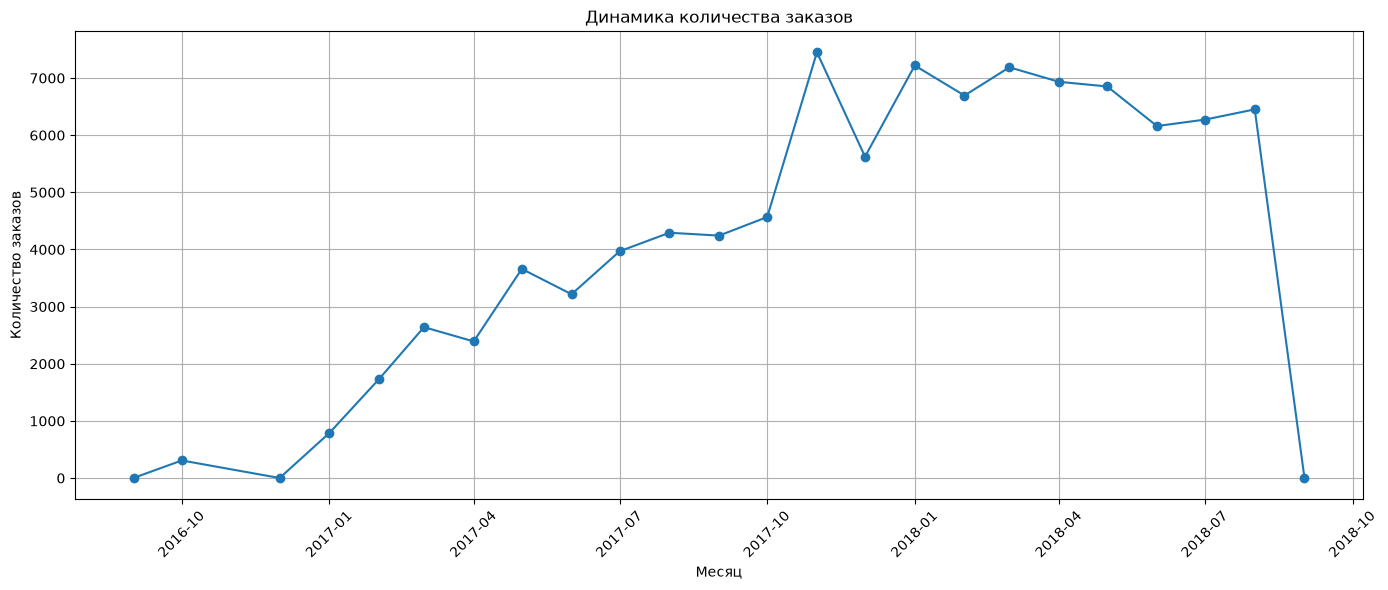

In [48]:
sales_pd = sales_by_month.toPandas()

sales_pd["month"] = pd.to_datetime(
    sales_pd["month"]
)

plt.figure(figsize=(14, 6))

plt.plot(
    sales_pd["month"],
    sales_pd["orders_count"],
    marker="o"
)

plt.title("Динамика количества заказов")
plt.xlabel("Месяц")
plt.ylabel("Количество заказов")
plt.grid(True)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

#### Динамика выручки

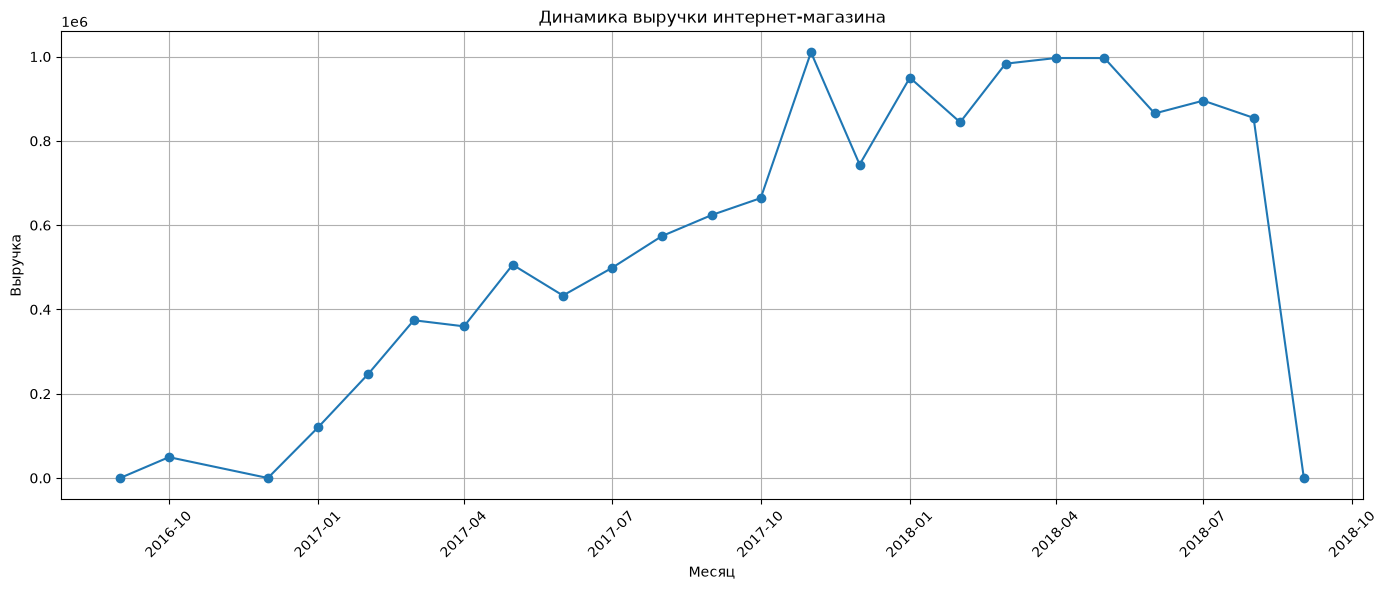

In [49]:
plt.figure(figsize=(14, 6))

plt.plot(
    sales_pd["month"],
    sales_pd["revenue"],
    marker="o"
)

plt.title("Динамика выручки интернет-магазина")
plt.xlabel("Месяц")
plt.ylabel("Выручка")
plt.grid(True)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

#### Топ-10 категорий по выручке

c:\Users\Nikita\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pyspark\sql\pandas\conversion.py:374: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


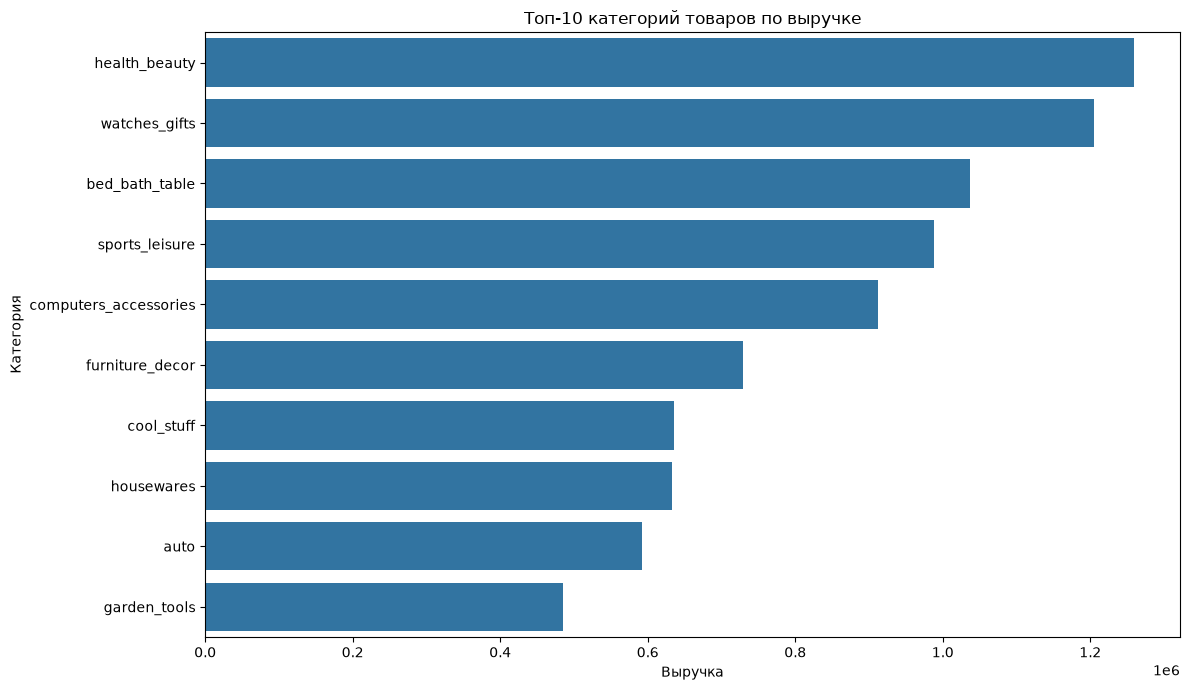

In [50]:
category_pd = category_sales.toPandas()

category_top10 = (
    category_pd
    .dropna(subset=["product_category_name_english"])
    .head(10)
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=category_top10,
    x="revenue",
    y="product_category_name_english"
)

plt.title("Топ-10 категорий товаров по выручке")
plt.xlabel("Выручка")
plt.ylabel("Категория")

plt.tight_layout()
plt.show()

#### Распределение оценок покупателей

c:\Users\Nikita\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pyspark\sql\pandas\conversion.py:374: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


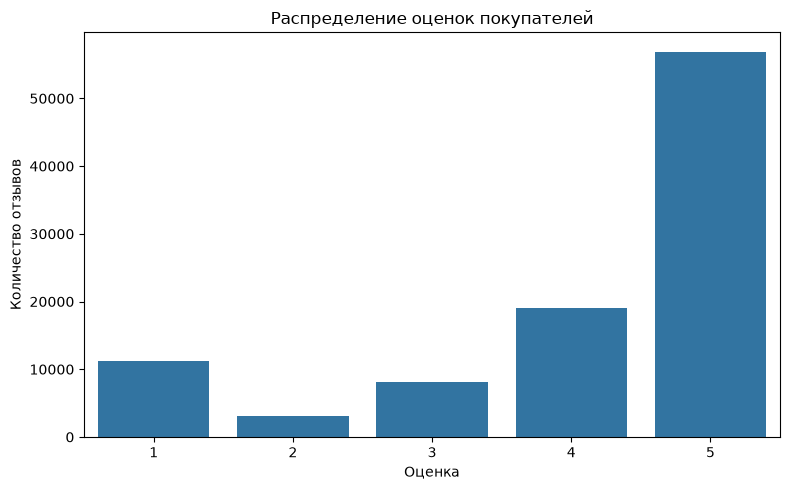

In [51]:
review_pd = review_distribution.toPandas()

plt.figure(figsize=(8, 5))

sns.barplot(
    data=review_pd,
    x="review_score",
    y="count"
)

plt.title("Распределение оценок покупателей")
plt.xlabel("Оценка")
plt.ylabel("Количество отзывов")

plt.tight_layout()
plt.show()

#### Географическое распределение заказов

c:\Users\Nikita\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pyspark\sql\pandas\conversion.py:374: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


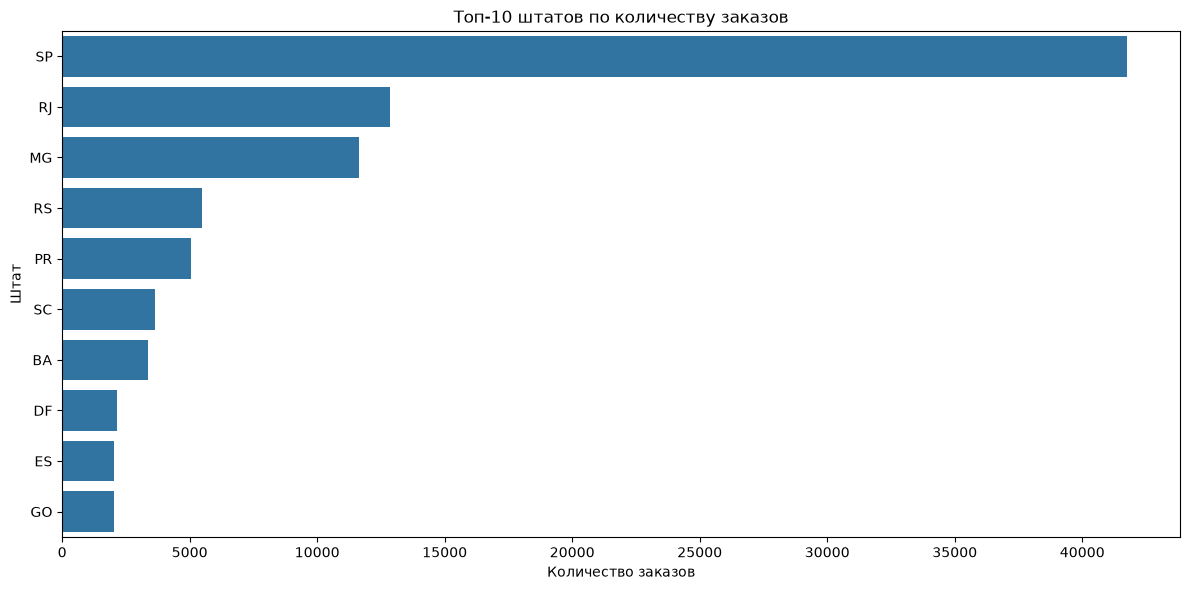

In [52]:
state_pd = orders_by_state.toPandas()

state_top10 = state_pd.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=state_top10,
    x="orders_count",
    y="customer_state"
)

plt.title("Топ-10 штатов по количеству заказов")
plt.xlabel("Количество заказов")
plt.ylabel("Штат")

plt.tight_layout()
plt.show()

#### Распределение сроков доставки

c:\Users\Nikita\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pyspark\sql\pandas\conversion.py:374: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


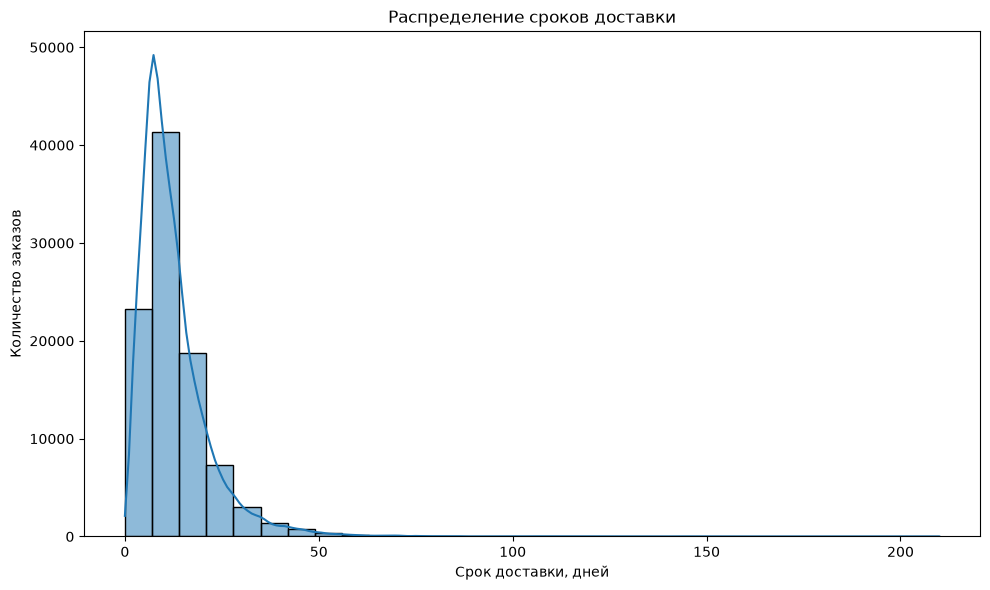

In [53]:
delivery_pd = delivery_data.select(
    "delivery_days"
).toPandas()

plt.figure(figsize=(10, 6))

sns.histplot(
    delivery_pd["delivery_days"],
    bins=30,
    kde=True
)

plt.title("Распределение сроков доставки")
plt.xlabel("Срок доставки, дней")
plt.ylabel("Количество заказов")

plt.tight_layout()
plt.show()

### 8. Сохранение очищенных данных

На заключительном этапе очищенные данные и результаты аналитической обработки сохраняются для дальнейшего использования. Основные таблицы записываются в формате Parquet, обеспечивающем эффективное хранение и обработку больших объёмов данных. Аналитические результаты дополнительно сохраняются в CSV-файлах для последующего изучения, использования в отчётах и построения визуализаций.

Сохраним очищенные таблицы в формате Parquet:

In [55]:
OUTPUT_PATH = "../data/output"

orders_clean.write.mode("overwrite").parquet(
    f"{OUTPUT_PATH}/orders_clean"
)

order_items_clean.write.mode("overwrite").parquet(
    f"{OUTPUT_PATH}/order_items_clean"
)

products_clean.write.mode("overwrite").parquet(
    f"{OUTPUT_PATH}/products_clean"
)

customers_clean.write.mode("overwrite").parquet(
    f"{OUTPUT_PATH}/customers_clean"
)

reviews_clean.write.mode("overwrite").parquet(
    f"{OUTPUT_PATH}/reviews_clean"
)

Основной аналитический набор:

In [56]:
orders_full.write.mode("overwrite").parquet(
    f"{OUTPUT_PATH}/olist_analytics"
)

Можно сохранить агрегированные таблицы в CSV

In [57]:
sales_by_month.coalesce(1).write \
    .mode("overwrite") \
    .option("header", True) \
    .csv(f"{OUTPUT_PATH}/sales_by_month")

category_sales.coalesce(1).write \
    .mode("overwrite") \
    .option("header", True) \
    .csv(f"{OUTPUT_PATH}/category_sales")